## initial analysis of BioModels, JWS, and CellML annotations

In [26]:
from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.mpl_cache'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data'
OUTPUT = DATA / 'analysis' / 'annotation_coverage'
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 100)

## load the saved data

In [27]:
def read_csv(relative_path):
    path = DATA / relative_path
    return pd.read_csv(path, low_memory=False) if path.exists() else pd.DataFrame()

# curated biomodels
bio_inventory = read_csv('detailed_curated/model_inventory.csv')
bio_annotations = read_csv('detailed_curated/annotated_elements.csv')
bio_raw = read_csv('curated/raw/parameters_raw.csv')

# JWS
jws_inventory = read_csv('jws/model_inventory.csv')
jws_annotations = read_csv('jws/annotated_elements.csv')

# JWS complete inventory includes annotated and unannotated SBML elements for every model.
jws_element_inventory = read_csv('jws/complete_element_inventory.csv')

# CellML
cellml_audit = read_csv('detailed_cellml/cellml_model_audit.csv')
cellml_annotations = read_csv('detailed_cellml/cellml_annotations_values.csv')
cellml_variables = read_csv('detailed_cellml/cellml_quantified_elements.csv')
cellml_element_inventory = read_csv('detailed_cellml/cellml_element_inventory.csv')

# print the nuber of models and annotations for each database
input_summary = pd.DataFrame([
    {'database': 'Curated BioModels', 'models': len(bio_inventory), 'annotation rows': len(bio_annotations)},
    {'database': 'JWS', 'models': len(jws_inventory), 'annotation rows': len(jws_annotations)},
    {'database': 'CellML', 'models': len(cellml_audit), 'annotation rows': len(cellml_annotations)},
])
display(input_summary)

,database,models,annotation rows
0,Curated BioModels,1096,112647
1,JWS,676,11018
2,CellML,1056,520


## get the number of models with annotations

In [28]:
def count_positive(values):
    values = pd.to_numeric(values, errors='coerce').fillna(0)
    return int(values.gt(0).sum())

annotation_summary = pd.DataFrame([
    {'database': 'Curated BioModels', 'models_extracted': len(bio_inventory),
     'models_with_annotations': count_positive(bio_inventory['Direct RDF links'])},
    {'database': 'JWS', 'models_extracted': len(jws_inventory),
     'models_with_annotations': count_positive(jws_inventory['Direct RDF links'])},
    {'database': 'CellML', 'models_extracted': len(cellml_audit),
     'models_with_annotations': count_positive(cellml_audit['Annotation links'])},
])

annotation_summary['annotation_%'] = annotation_summary['models_with_annotations']/annotation_summary['models_extracted']*100
annotation_summary['models_without_annotations'] = (annotation_summary['models_extracted'] - annotation_summary['models_with_annotations'])
display(annotation_summary)

,database,models_extracted,models_with_annotations,annotation_%,models_without_annotations
0,Curated BioModels,1096,1042,95.072993,54
1,JWS,676,334,49.408284,342
2,CellML,1056,16,1.515152,1040


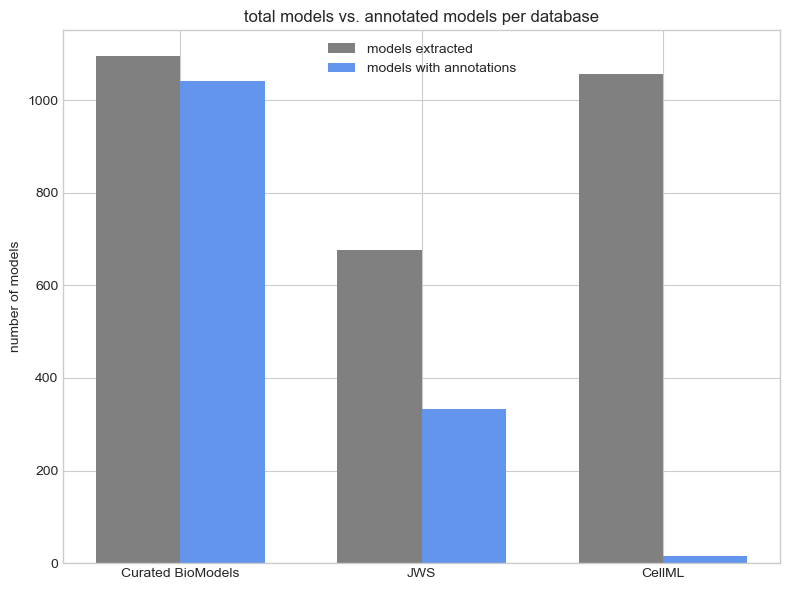

In [29]:
# plot the total models vs models w/annotations
fig, ax = plt.subplots(figsize=(8, 6))
x = np.arange(len(annotation_summary)); width = 0.35

ax.bar(x - width/2, annotation_summary['models_extracted'], width, label='models extracted', color="grey")
ax.bar( x + width/2, annotation_summary['models_with_annotations'], width, label='models with annotations', color="cornflowerblue")

ax.set_xticks(x)
ax.set_xticklabels(annotation_summary.database)
ax.set_ylabel('number of models')
ax.set_title('total models vs. annotated models per database')
ax.legend()

plt.tight_layout()
plt.show()

In [31]:
def count_direct_elements(frame, database):
    if database == 'CellML':
        id_col, url_col, model_col, element_col = ('Database ID', 'Annotation link', 'CellML model', 'Annotated model element')
    else:
        id_col, url_col, model_col, element_col = ('Annotation IDs', 'Annotation URLs', 'Model', 'Element ID')
    has_id = frame[id_col].fillna('').astype(str).str.strip().ne('')
    has_url = frame[url_col].fillna('').astype(str).str.strip().ne('')
    selected = frame.loc[(has_id | has_url) & frame[element_col].notna(), [model_col, 'Element type', element_col]].copy()
    return selected.drop_duplicates([model_col, 'Element type', element_col])

def type_counts_by_model(direct):
    return direct.groupby(['Model', 'Element type'])['Element ID'].nunique().unstack(fill_value=0)

bio_direct = count_direct_elements(bio_annotations, 'BioModels')
jws_direct = count_direct_elements(jws_annotations, 'JWS')
cellml_direct = count_direct_elements(cellml_annotations, 'CellML')

# BioModels - from curated inventory
# JWS - from the complete element inventory (every element whether annotated or not - to get totals)
bio_all_counts = bio_raw.groupby(['model_id', 'record_type']).size().unstack(fill_value=0)
bio_cov = bio_inventory.rename(columns={'Model': 'model_id'}).copy()
bio_cov['total_species'] = bio_cov['model_id'].map(bio_all_counts.get('species', pd.Series(dtype=float)))
bio_cov['total_compartments'] = bio_cov['model_id'].map(bio_all_counts.get('compartment_size', pd.Series(dtype=float)))
bio_cov['total_reactions'] = pd.to_numeric(bio_cov['Total reactions'], errors='coerce')

# direct annotation = at least one annotation ID or URL for that element
def inventory_model_counts(inventory, model_column, type_column, id_column, flag_column=None):
    frame = inventory.dropna(subset=[model_column, type_column, id_column]).drop_duplicates([model_column, type_column, id_column]).copy()
    if flag_column and flag_column in frame.columns:
        frame['_direct'] = frame[flag_column].fillna(False).astype(str).str.lower().isin(['true', '1', 'yes'])
    else:
        ids = frame.get('Annotation IDs', pd.Series('', index=frame.index)).fillna('').astype(str).str.strip().ne('')
        urls = frame.get('Annotation URLs', pd.Series('', index=frame.index)).fillna('').astype(str).str.strip().ne('')
        frame['_direct'] = ids | urls
    totals = frame.groupby([model_column, type_column])[id_column].nunique().unstack(fill_value=0)
    direct = frame[frame['_direct']].groupby([model_column, type_column])[id_column].nunique().unstack(fill_value=0)
    return totals, direct

# get biomodel element counts
bio_type_counts = type_counts_by_model(bio_direct)
for column, element_type in [('annotated_species', 'species'), ('annotated_reactions', 'reaction'), ('annotated_compartments', 'compartment')]:
    bio_cov[column] = bio_cov['model_id'].map(bio_type_counts.get(element_type, pd.Series(dtype=float))).fillna(0)

# get jws totals and counts
jws_totals, jws_direct_totals = inventory_model_counts(jws_element_inventory, 'Model', 'Element type', 'Element ID', 'Is directly annotated')
jws_cov = jws_inventory.rename(columns={'Model': 'model_id'}).copy()
for column, element_type in [('total_species', 'species'), ('total_reactions', 'reaction'), ('total_compartments', 'compartment')]:
    jws_cov[column] = jws_cov['model_id'].map(jws_totals.get(element_type, pd.Series(dtype=float))).fillna(0)
for column, element_type in [('annotated_species', 'species'), ('annotated_reactions', 'reaction'), ('annotated_compartments', 'compartment')]:
    jws_cov[column] = jws_cov['model_id'].map(jws_direct_totals.get(element_type, pd.Series(dtype=float))).fillna(0)

# compute coverage
def coverage_percent(annotated, total):
    annotated = pd.to_numeric(annotated, errors='coerce')
    total = pd.to_numeric(total, errors='coerce')
    return (100 * annotated / total).where(total > 0)

# store in dataframe
for frame in (bio_cov, jws_cov):
    frame['species_coverage_pct'] = coverage_percent(frame['annotated_species'], frame['total_species'])
    frame['reaction_coverage_pct'] = coverage_percent(frame['annotated_reactions'], frame['total_reactions'])
    frame['compartment_coverage_pct'] = coverage_percent(frame['annotated_compartments'], frame['total_compartments'])

coverage_by_model = pd.concat([bio_cov.assign(database='Curated BioModels'), jws_cov.assign(database='JWS')], ignore_index=True)
print(f'Per-model BioModels + JWS coverage rows: {len(coverage_by_model):,} '
      f'({len(bio_cov):,} BioModels; {len(jws_cov):,} JWS).')
display(coverage_by_model)


Per-model BioModels + JWS coverage rows: 1,772 (1,096 BioModels; 676 JWS).


,model_id,Organism,Tissue,Process,Model type,Download status,Directly annotated elements,Annotated species,Annotated reactions,Total reactions,Total parameters,Direct RDF links,SBML SHA256,Error,SBML source URL,Model page URL,total_species,total_compartments,total_reactions,annotated_species,annotated_reactions,annotated_compartments,species_coverage_pct,reaction_coverage_pct,compartment_coverage_pct,database,Total species,Total compartments,Annotated compartments
0,BIOMD0000000001,NaN,NaN,NaN,NaN,ok,56,24,28,34,70,80,4371fba94367154a53f921dca30963ffa962caa93c5fe4...,NaN,https://www.biomodels.org/model/download/BIOMD...,https://www.biomodels.org/BIOMD0000000001,24.0,2.0,34,12.0,14.0,1.0,50.000000,41.176471,50.0,Curated BioModels,NaN,NaN,NaN
1,BIOMD0000000002,NaN,NaN,NaN,NaN,ok,28,13,14,17,34,39,9f8127bc551f74da1cb310a6d6690e7229fce031c03b15...,NaN,https://www.biomodels.org/model/download/BIOMD...,https://www.biomodels.org/BIOMD0000000002,13.0,1.0,17,13.0,14.0,1.0,100.000000,82.352941,100.0,Curated BioModels,NaN,NaN,NaN
2,BIOMD0000000003,NaN,NaN,NaN,NaN,ok,9,3,5,7,15,16,e2ffb1387182adf43a388c58235d03140d238b5447984b...,NaN,https://www.biomodels.org/model/download/BIOMD...,https://www.biomodels.org/BIOMD0000000003,3.0,1.0,7,3.0,5.0,1.0,100.000000,71.428571,100.0,Curated BioModels,NaN,NaN,NaN
3,BIOMD0000000004,NaN,NaN,NaN,NaN,ok,9,3,5,7,15,15,868edf72456fcb4518862d41e8b7b0a631f9ad54485836...,NaN,https://www.biomodels.org/model/download/BIOMD...,https://www.biomodels.org/BIOMD0000000004,5.0,1.0,7,3.0,5.0,1.0,60.000000,71.428571,100.0,Curated BioModels,NaN,NaN,NaN
4,BIOMD0000000005,NaN,NaN,NaN,NaN,ok,18,8,9,9,10,33,fbd85625cd0f997e9e360bbc83dcbeb6854b1a84842a85...,NaN,https://www.biomodels.org/model/download/BIOMD...,https://www.biomodels.org/BIOMD0000000005,9.0,1.0,9,8.0,9.0,1.0,88.888889,100.000000,100.0,Curated BioModels,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1767,zeilinger2,Arabidopsis thaliana,—,gene regulation,—,ok,64,16,46,46,94,76,368d4cbd98dd59720c916a712f999e573589f00c38349f...,NaN,https://jjj.mib.ac.uk/models/zeilinger2/sbml/?...,https://jjj.mib.ac.uk/models/zeilinger2/,19.0,2.0,46,16.0,46.0,2.0,84.210526,100.000000,100.0,JWS,19.0,2.0,2.0
1768,zeilinger3,Arabidopsis thaliana,—,gene regulation,—,ok,64,16,46,46,93,76,f9db5128bcb5bf5426b4537c2d2872a5442fa90e96b653...,NaN,https://jjj.mib.ac.uk/models/zeilinger3/sbml/?...,https://jjj.mib.ac.uk/models/zeilinger3/,19.0,2.0,46,16.0,46.0,2.0,84.210526,100.000000,100.0,JWS,19.0,2.0,2.0
1769,zhao1,Homo sapiens,—,epidemiological,—,ok,0,0,0,10,10,0,a501d681b4e9b98e2ece4336d5f22fbfae2859a3925e75...,NaN,https://jjj.mib.ac.uk/models/zhao1/sbml/?downl...,https://jjj.mib.ac.uk/models/zhao1/,5.0,1.0,10,0.0,0.0,0.0,0.000000,0.000000,0.0,JWS,5.0,1.0,0.0
1770,zhu1,Homo sapiens,—,other,—,ok,12,2,9,9,22,16,cc7bb0a266a236df87a18a309d9783a7d638103543686d...,NaN,https://jjj.mib.ac.uk/models/zhu1/sbml/?downlo...,https://jjj.mib.ac.uk/models/zhu1/,3.0,2.0,9,2.0,9.0,1.0,66.666667,100.000000,50.0,JWS,3.0,2.0,1.0


### explore per-model coverage

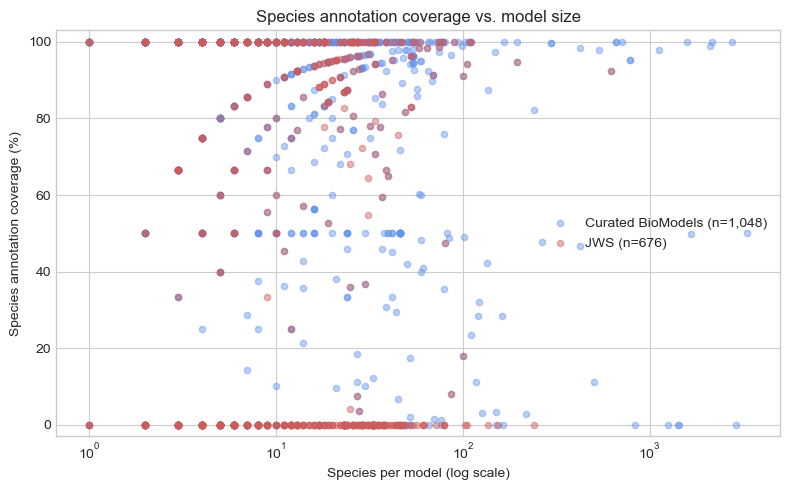

In [ ]:
# explore whether model species count relates to species annotation coverage.
fig, ax = plt.subplots(figsize=(8, 5))
colors = {'Curated BioModels': 'cornflowerblue', 'JWS': 'indianred'}
for database, group in coverage_by_model.groupby('database'):
    points = group.dropna(subset=['total_species', 'species_coverage_pct'])
    ax.scatter(points['total_species'], points['species_coverage_pct'],
               s=20, alpha=0.45, label=f'{database} (n={len(points):,})',
               color=colors.get(database))
ax.set_xscale('log')
ax.set_xlabel('Species per model (log scale)')
ax.set_ylabel('Species annotation coverage (%)')
ax.set_ylim(-3, 103)
ax.set_title('Species annotation coverage vs. model size')
ax.legend()
plt.tight_layout()
plt.show()

Each dot is one model. The horizontal axis is its number of species on a log scale. The vertical axis is the percentage of its species with direct annotations. This shows whether coverage changes with model size.

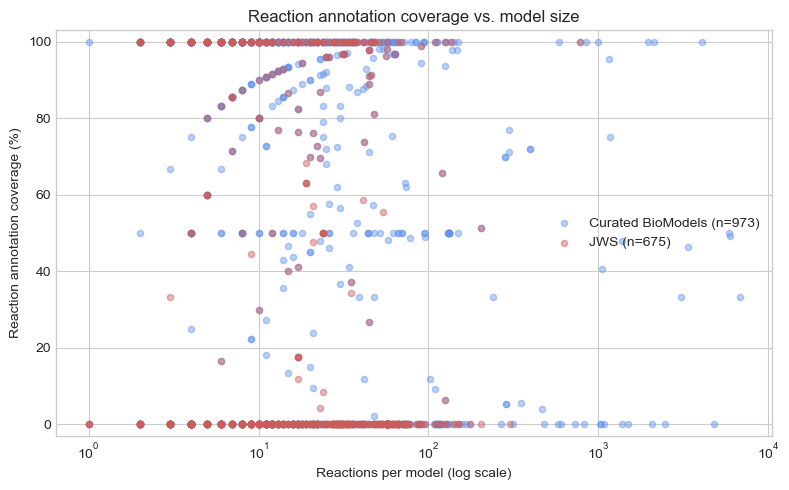

In [60]:
# Explore reaction coverage against reaction counts for each model.
fig, ax = plt.subplots(figsize=(8, 5))
for database, group in coverage_by_model.groupby('database'):
    points = group.dropna(subset=['total_reactions', 'reaction_coverage_pct'])
    ax.scatter(points['total_reactions'], points['reaction_coverage_pct'],
               s=20, alpha=0.45, label=f'{database} (n={len(points):,})',
               color=colors.get(database))
ax.set_xscale('log')
ax.set_xlabel('Reactions per model (log scale)')
ax.set_ylabel('Reaction annotation coverage (%)')
ax.set_ylim(-3, 103)
ax.set_title('Reaction annotation coverage vs. model size')
ax.legend()
plt.tight_layout()
plt.show()


This shows if larger reaction networks have different reaction coverages.

## average coverage by database and element

In [42]:
coverage_columns = {'species_coverage_pct': 'Species', 'reaction_coverage_pct': 'Reactions', 
                    'compartment_coverage_pct': 'Compartments'}

coverage_long = coverage_by_model.melt(
    id_vars=['database', 'model_id'], value_vars=list(coverage_columns),
    var_name='element_type', value_name='coverage_pct').dropna(subset=['coverage_pct'])
coverage_long['element_type'] = coverage_long['element_type'].map(coverage_columns)

coverage_summary = (coverage_long.groupby(['database', 'element_type'])['coverage_pct']
                   .agg(models='count', mean_per_model_pct='mean', median_per_model_pct='median')
                   .reset_index())

display(coverage_summary)

,database,element_type,models,mean_per_model_pct,median_per_model_pct
0,Curated BioModels,Compartments,1075,70.844444,100.000000
1,Curated BioModels,Reactions,973,65.370405,96.551724
2,Curated BioModels,Species,1048,84.435027,100.000000
3,JWS,Compartments,676,33.433185,0.000000
4,JWS,Reactions,675,27.717502,0.000000
5,JWS,Species,676,41.179530,0.000000


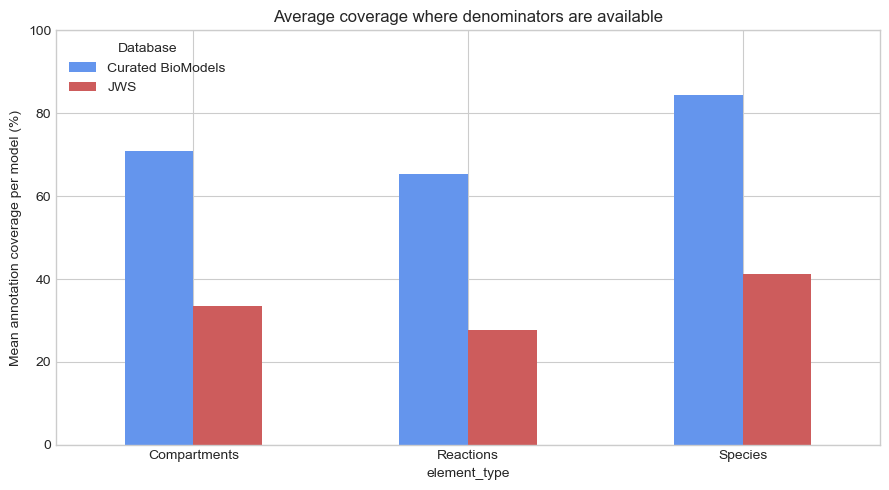

In [ ]:
# plot average coverage per annotation type per database
coverage_plot = coverage_summary.pivot(index='element_type', columns='database', values='mean_per_model_pct')
ax = coverage_plot.plot(kind='bar', figsize=(9, 5), color=["cornflowerblue", "indianred"])
ax.set_ylabel('Mean annotation coverage per model (%)')
ax.set_title('Average coverage where denominators are available')
ax.set_ylim(0, 100)
ax.legend(title='Database')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## overall summary per database
- JWS: annotated elements table gives annotated counts but not total species or compartment counts, so these coverage percentages are unavailable
- CellML: element types are not of the three SBML types, so they are not included

In [45]:
def total_or_missing(values):
    numeric = pd.to_numeric(values, errors='coerce')
    return numeric.sum(min_count=1)

def database_row(database, model_count, model_frame):
    row = {'database': database, 'total_models': model_count}
    for element, annotated_col, total_col in [
        ('species', 'annotated_species', 'total_species'),
        ('reactions', 'annotated_reactions', 'total_reactions'),
        ('compartments', 'annotated_compartments', 'total_compartments'),
    ]:
        annotated = total_or_missing(model_frame[annotated_col])
        total = total_or_missing(model_frame[total_col])
        row[f'total_{element}'] = total
        row[f'annotated_{element}'] = annotated
        row[f'{element}_coverage_pct'] = (100 * annotated / total) if pd.notna(total) and total > 0 else pd.NA
    return row

overall_coverage = pd.DataFrame([
    database_row('Curated BioModels', len(bio_inventory), bio_cov),
    database_row('JWS', len(jws_inventory), jws_cov),
])
cellml_empty = pd.DataFrame({
    'annotated_species': [pd.NA], 'total_species': [pd.NA],
    'annotated_reactions': [pd.NA], 'total_reactions': [pd.NA],
    'annotated_compartments': [pd.NA], 'total_compartments': [pd.NA],
})
overall_coverage = pd.concat([overall_coverage, pd.DataFrame([
    database_row('CellML', len(cellml_audit), cellml_empty)
])], ignore_index=True)


display(overall_coverage)

/var/folders/2l/987jsx797pb9xrgxhcngwht40000gn/T/ipykernel_56375/2285006258.py:28: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  overall_coverage = pd.concat([overall_coverage, pd.DataFrame([


,database,total_models,total_species,annotated_species,species_coverage_pct,total_reactions,annotated_reactions,reactions_coverage_pct,total_compartments,annotated_compartments,compartments_coverage_pct
0,Curated BioModels,1096,49736.0,39323.0,79.063455,88858.0,40164.0,45.200207,2046.0,1277.0,62.414467
1,JWS,676,13651.0,5821.0,42.641565,17863.0,4682.0,26.210603,1017.0,354.0,34.808260
2,CellML,1056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [46]:
annotated_element_counts = pd.concat([
    bio_direct.groupby('Element type').size().rename('annotated_elements').reset_index().assign(database='Curated BioModels'),
    jws_direct.groupby('Element type').size().rename('annotated_elements').reset_index().assign(database='JWS'),
    cellml_direct.groupby('Element type').size().rename('annotated_elements').reset_index().assign(database='CellML'),
], ignore_index=True)

display(annotated_element_counts.sort_values(['database', 'annotated_elements'], ascending=[True, False]))

,Element type,annotated_elements,database
20,Variable,354,CellML
19,Model,2,CellML
8,reaction,40164,Curated BioModels
9,species,39323,Curated BioModels
4,geneProduct,9157,Curated BioModels
6,parameter,2137,Curated BioModels
1,compartment,1277,Curated BioModels
5,kineticLaw,45,Curated BioModels
2,event,43,Curated BioModels
0,assignmentRule,34,Curated BioModels


## CellML annotation coverage - uses variables

In [48]:
# Use stable Model ID and unique element IDs. Start from the audit so models with zero
# components or variables remain represented in the per-model table.
cellml_unique = cellml_element_inventory.dropna(subset=['Model ID', 'Element type', 'Element ID']).drop_duplicates(
    ['Model ID', 'Element type', 'Element ID'])
cellml_totals = cellml_unique.groupby(['Model ID', 'Element type'])['Element ID'].nunique().unstack(fill_value=0)
cellml_marked = cellml_unique[cellml_unique['Is directly annotated'].fillna(False).astype(str).str.lower().isin(['true', '1', 'yes'])]
cellml_annotated_counts = cellml_marked.groupby(['Model ID', 'Element type'])['Element ID'].nunique().unstack(fill_value=0)
cellml_coverage = cellml_audit[['Model ID', 'CellML model', 'Total components', 'Annotated components',
                                'Total variables', 'Annotated variables']].drop_duplicates('Model ID').copy()
cellml_coverage = cellml_coverage.rename(columns={'Total components': 'total_components',
    'Annotated components': 'audit_annotated_components', 'Total variables': 'total_variables',
    'Annotated variables': 'audit_annotated_variables'})
cellml_coverage = cellml_coverage.set_index('Model ID')
cellml_coverage['total_components'] = cellml_coverage.index.map(cellml_totals.get('Component', pd.Series(dtype=float))).fillna(0).astype(int)
cellml_coverage['total_variables'] = cellml_coverage.index.map(cellml_totals.get('Variable', pd.Series(dtype=float))).fillna(0).astype(int)
cellml_coverage['annotated_components'] = cellml_coverage.index.map(cellml_annotated_counts.get('Component', pd.Series(dtype=float))).fillna(0).astype(int)
cellml_coverage['annotated_variables'] = cellml_coverage.index.map(cellml_annotated_counts.get('Variable', pd.Series(dtype=float))).fillna(0).astype(int)
cellml_coverage['coverage_pct'] = coverage_percent(cellml_coverage['annotated_variables'], cellml_coverage['total_variables'])
cellml_coverage_summary = cellml_coverage['coverage_pct'].describe().to_frame('CellML variable coverage (%)')
print(f'CellML models represented: {len(cellml_coverage):,}; '
      f'models with annotated variables: {int(cellml_coverage["annotated_variables"].gt(0).sum()):,}.')
display(cellml_coverage_summary)


CellML models represented: 1,056; models with annotated variables: 15.


,CellML variable coverage (%)
count,987.000000
mean,0.145729
std,1.832032
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,48.717949


## annotation element types and annotation identifiers

In [52]:
def identifier_namespaces(frame, database):
    if frame.empty or 'Annotation IDs' not in frame:
        return pd.DataFrame(columns=['database', 'namespace', 'count'])
    ids = frame['Annotation IDs'].fillna('').astype(str).str.split('; ').explode().str.strip()
    ids = ids[ids.ne('')]
    namespaces = ids.str.split(':', n=1).str[0].str.lower()
    return namespaces.value_counts().rename_axis('namespace').reset_index(name='count').assign(database=database)

namespace_summary = pd.concat([
    identifier_namespaces(bio_annotations, 'Curated BioModels'),
    identifier_namespaces(jws_annotations, 'JWS'),
], ignore_index=True)
display(namespace_summary.sort_values(['database', 'count'], ascending=[True, False]).groupby('database').head(15))

,namespace,count,database
0,chebi,91837,Curated BioModels
1,reactome.reaction,50439,Curated BioModels
2,rhea,37882,Curated BioModels
3,biocyc,29861,Curated BioModels
4,bigg.reaction,27629,Curated BioModels
5,ec,26995,Curated BioModels
6,metanetx.reaction,26203,Curated BioModels
7,kegg compound,24753,Curated BioModels
8,metanetx.chemical,23137,Curated BioModels
9,seed.reaction,22709,Curated BioModels


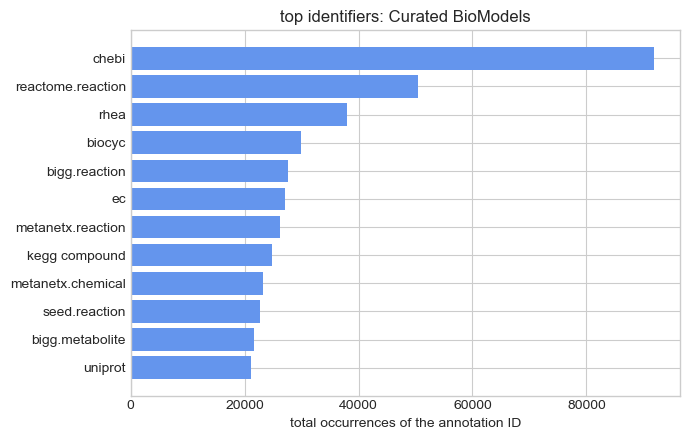

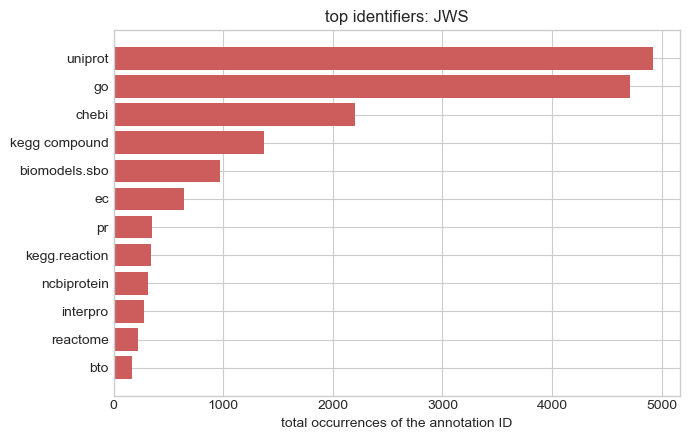

In [56]:
namespace_plot = namespace_summary.groupby(['database', 'namespace'])['count'].sum().reset_index()
for database in namespace_plot['database'].unique():
    subset = namespace_plot[namespace_plot['database'].eq(database)].nlargest(12, 'count').sort_values('count')
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh(subset['namespace'], subset['count'], color="cornflowerblue" if database.startswith('Curated') else "indianred")
    ax.set_title(f'top identifiers: {database}')
    ax.set_xlabel('total occurrences of the annotation ID')
    plt.tight_layout()
    plt.show()

## Save analysis tables

In [ ]:
OUTPUT.mkdir(parents=True, exist_ok=True)
input_summary.to_csv(OUTPUT / 'input_table_row_counts.csv', index=False)
annotation_summary.to_csv(OUTPUT / 'models_with_annotations_by_database.csv', index=False)
coverage_summary.to_csv(OUTPUT / 'annotation_coverage_summary.csv', index=False)
coverage_by_model.to_csv(OUTPUT / 'annotation_coverage_by_model.csv', index=False)
overall_coverage.to_csv(OUTPUT / 'overall_database_coverage.csv', index=False)
annotated_element_counts.to_csv(OUTPUT / 'annotated_element_counts_by_database.csv', index=False)
cellml_coverage.to_csv(OUTPUT / 'cellml_variable_coverage_by_model.csv', index=True)
print(f'Saved {len(coverage_by_model):,} BioModels/JWS model rows and {len(cellml_coverage):,} CellML model rows.')
namespace_summary.to_csv(OUTPUT / 'annotation_namespace_counts.csv', index=False)
print(f'Saved summaries to {OUTPUT}')